# Gurobi MIQP vs OR-Tools CP-SAT vs SQBM+ — report figures

IEA Task 37 case study 4 (81 turbines). Multi-resolution scheme: global solve at coarse grid, then local refinement warm-started from the previous layout. This notebook only **reads** results and produces report-ready figures in `results/report_figures/`.

In [1]:
import sys
import io
import contextlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

sys.path.append("..")
from src.qubo_windfarm_layout.evaluation import (
    layouts_folder_to_df,
    load_layout_coordinates,
    get_benchmark_comparison,
)
from src.qubo_windfarm_layout.model import (
    get_farm_area,
    build_local_wake_loss_matrix_optimized,
)

ROOT = Path("..").resolve()
LAYOUTS_DIR = ROOT / "results" / "layouts"
FIG_DIR = ROOT / "results" / "report_figures"
CACHE_PATH = ROOT / "results" / "precomputed" / "report_best_L.npz"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Okabe-Ito colour-blind-safe palette, one fixed colour/marker per solver
SOLVERS = {
    "Gurobi MIQP":     dict(folder="gurobi_miqp",    color="#0072B2", marker="o"),
    "OR-Tools CP-SAT": dict(folder="ortools_cpsat",  color="#E69F00", marker="s"),
    "SQBM+":           dict(folder="sqbm_qubo",      color="#009E73", marker="^"),
}
REF_COLORS = {"Baseline": "#7f7f7f", "DEBO": "#CC79A7"}
MIN_SPACING = 396.0  # 2 rotor diameters [m]
N_TURBINES = 81

mpl.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "pdf.fonttype": 42,
})

def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", bbox_inches="tight")

def quiet(fn, *args, **kwargs):
    """Run fn silencing its stdout (the physics helpers are chatty)."""
    with contextlib.redirect_stdout(io.StringIO()):
        return fn(*args, **kwargs)


## 1. Load all layouts
AEP, wake loss, minimum distance and validity are read from the `metadata` / `cached_metrics` stored in each layout YAML (no physics re-evaluation). The `solver` metadata field is inconsistent, so the solver label comes from the folder name.

In [2]:
rows = []
for label, cfg in SOLVERS.items():
    folder = LAYOUTS_DIR / cfg["folder"]
    meta = layouts_folder_to_df(folder)
    for _, r in meta.iterrows():
        rows.append({
            "solver": label,
            "file": r["file"],
            "key": f"{cfg['folder']}/{r['file']}",
            "stage": "local" if "local" in r["file"] else "global",
            "resolution": float(r["grid_resolution"]),
            "time_limit_s": r["time_limit_s"],
            "h_pairwise_gwh": r["h_qubo"] / 1000.0,  # NaN for global solves
            "aep_gwh": r["aep_gwh"],
            "wake_loss_pct": r["wake_loss_pct"],
            "min_distance_m": r["min_distance_m"],
            "valid_cardinality": r["valid_cardinality"],
            "valid_spacing": r["valid_spacing"],
            "valid_boundary": r["valid_boundary"],
            "valid": r["valid"],
            "path": folder / r["file"],
        })

df = pd.DataFrame(rows)
df = df.sort_values(["solver", "resolution", "stage"], ascending=[True, False, True]).reset_index(drop=True)
# unconstrained AEP (81 isolated turbines) implied by the stored AEP and wake loss
ideal_gwh = (df["aep_gwh"] / (1 - df["wake_loss_pct"] / 100)).median()
df["wake_loss_gwh"] = df["wake_loss_pct"] / 100 * ideal_gwh

# Reference results (Thomas et al. 2023)
ref = get_benchmark_comparison().set_index("method")
BASELINE = ref.loc["Baseline"]
BEST_REF = ref.loc["DEBO"]
print(f"{len(df)} layouts loaded | ideal AEP {ideal_gwh:.1f} GWh")
print(f"Baseline {BASELINE.aep_gwh:.1f} GWh | DEBO {BEST_REF.aep_gwh:.1f} GWh")
df.drop(columns="path").round(3)

Single turbine AEP: 42.550 GWh/year
Loaded 9 reference layouts.
26 layouts loaded | ideal AEP 3446.5 GWh
Baseline 2851.1 GWh | DEBO 2913.2 GWh


,solver,file,key,stage,resolution,time_limit_s,h_pairwise_gwh,aep_gwh,wake_loss_pct,min_distance_m,valid_cardinality,valid_spacing,valid_boundary,valid,wake_loss_gwh
0,Gurobi MIQP,gurobi_128_3600s.yaml,gurobi_miqp/gurobi_128_3600s.yaml,global,128.0,NaN,NaN,2882.551,16.364,512.000,True,True,True,True,563.985
1,Gurobi MIQP,gurobi_local_128m_1800s_warmstart.yaml,gurobi_miqp/gurobi_local_128m_1800s_warmstart....,local,128.0,1800.0,859.717,2883.059,16.349,512.000,True,True,True,True,563.477
2,Gurobi MIQP,gurobi_local_64m_1800s_warmstart.yaml,gurobi_miqp/gurobi_local_64m_1800s_warmstart.yaml,local,64.0,1800.0,846.557,2892.778,16.067,448.000,True,True,True,True,553.757
3,Gurobi MIQP,gurobi_local_32m_1800s_warmstart.yaml,gurobi_miqp/gurobi_local_32m_1800s_warmstart.yaml,local,32.0,1800.0,839.625,2897.871,15.919,448.000,True,True,True,True,548.664
4,Gurobi MIQP,gurobi_local_16m_1800s_warmstart.yaml,gurobi_miqp/gurobi_local_16m_1800s_warmstart.yaml,local,16.0,1800.0,836.292,2900.315,15.848,432.000,True,True,True,True,546.221
5,Gurobi MIQP,gurobi_local_8m_1800s_warmstart.yaml,gurobi_miqp/gurobi_local_8m_1800s_warmstart.yaml,local,8.0,1800.0,835.138,2901.043,15.827,440.073,True,True,True,True,545.492
6,Gurobi MIQP,gurobi_local_4m_1800s_warmstart.yaml,gurobi_miqp/gurobi_local_4m_1800s_warmstart.yaml,local,4.0,1800.0,834.516,2901.481,15.815,444.018,True,True,True,True,545.055
7,Gurobi MIQP,gurobi_local_2m_1800s_warmstart.yaml,gurobi_miqp/gurobi_local_2m_1800s_warmstart.yaml,local,2.0,1800.0,834.166,2901.708,15.808,444.005,True,True,True,True,544.827
8,OR-Tools CP-SAT,cpsat_256_3600s.yaml,ortools_cpsat/cpsat_256_3600s.yaml,global,256.0,3600.0,NaN,2853.762,17.199,512.000,True,True,True,True,592.774
9,OR-Tools CP-SAT,ortools_cpsat_local_256m_1800s_warmstart.yaml,ortools_cpsat/ortools_cpsat_local_256m_1800s_w...,local,256.0,1800.0,903.237,2855.005,17.163,512.000,True,True,True,True,591.531


## 2. Pairwise wake metric
$H=\\sum_{i<j}L_{ij}$ is the objective optimised by the QUBO / MIQP models (`h_qubo` in the YAML metadata, available for the local-refinement layouts). The full matrices $L_{ij}$ are only needed for the 3 best layouts (Figs. 5-6); they are computed once and cached in `results/precomputed/report_best_L.npz`.

In [3]:
best = {l: df[df.solver == l].sort_values("aep_gwh").iloc[-1] for l in SOLVERS}

def get_best_L():
    """Pairwise wake matrices [MWh] of each solver's best layout (cached)."""
    if CACHE_PATH.exists():
        z = np.load(CACHE_PATH)
        if all(b["key"] in z.files for b in best.values()):
            return {l: z[b["key"]] for l, b in best.items()}
    out = {l: quiet(build_local_wake_loss_matrix_optimized,
                    load_layout_coordinates(b["path"]), output_path=None)[0]
           for l, b in best.items()}
    CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(CACHE_PATH, **{best[l]["key"]: L for l, L in out.items()})
    return out

L_best_mwh = get_best_L()
for l, b in best.items():
    H = np.triu(L_best_mwh[l], 1).sum() / 1000
    print(f"{l}: best {b.file} | H recomputed {H:.2f} GWh | h_qubo metadata {b.h_pairwise_gwh:.2f} GWh")

Gurobi MIQP: best gurobi_local_2m_1800s_warmstart.yaml | H recomputed 834.17 GWh | h_qubo metadata 834.17 GWh
OR-Tools CP-SAT: best ortools_cpsat_local_2m_1800s_warmstart.yaml | H recomputed 837.42 GWh | h_qubo metadata 837.42 GWh
SQBM+: best sqbm_qubo_local_2m_60s_warmstart.yaml | H recomputed 848.52 GWh | h_qubo metadata 848.52 GWh


## Fig. 1 — Total AEP vs grid resolution

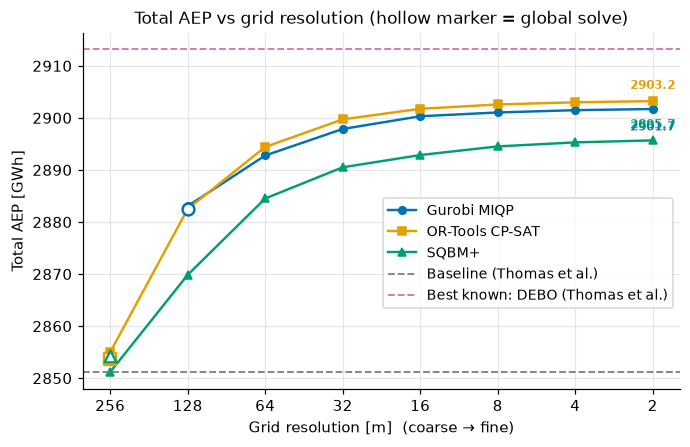

In [4]:
def res_axis(ax):
    ax.set_xscale("log", base=2)
    ax.set_xticks([256, 128, 64, 32, 16, 8, 4, 2])
    ax.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
    ax.minorticks_off()
    ax.invert_xaxis()  # coarse -> fine
    ax.set_xlabel("Grid resolution [m]  (coarse → fine)")

def plot_metric(ax, col, ylabel):
    for label, cfg in SOLVERS.items():
        d = df[df.solver == label]
        loc_ = d[d.stage == "local"]
        glo = d[d.stage == "global"]
        ax.plot(loc_.resolution, loc_[col], color=cfg["color"], marker=cfg["marker"],
                ms=5, lw=1.6, label=label)
        ax.scatter(glo.resolution, glo[col], facecolors="white", edgecolors=cfg["color"],
                   marker=cfg["marker"], s=60, linewidths=1.6, zorder=4)
    res_axis(ax)
    ax.set_ylabel(ylabel)

fig, ax = plt.subplots(figsize=(7, 4.2))
plot_metric(ax, "aep_gwh", "Total AEP [GWh]")
ax.axhline(BASELINE.aep_gwh, color=REF_COLORS["Baseline"], ls="--", lw=1.2, label="Baseline (Thomas et al.)")
ax.axhline(BEST_REF.aep_gwh, color=REF_COLORS["DEBO"], ls="--", lw=1.2, label="Best known: DEBO (Thomas et al.)")
for label, cfg in SOLVERS.items():
    b = df[df.solver == label].sort_values("aep_gwh").iloc[-1]
    ax.annotate(f"{b.aep_gwh:.1f}", (b.resolution, b.aep_gwh), textcoords="offset points",
                xytext=(0, 8 if label != "Gurobi MIQP" else -14), ha="center", color=cfg["color"], fontsize=8, fontweight="bold")
ax.set_title("Total AEP vs grid resolution (hollow marker = global solve)")
ax.legend(loc="center right", bbox_to_anchor=(1, 0.38))
save_fig(fig, "fig1_aep_vs_resolution")
plt.show()

## Fig. 2 — Wake effect vs grid resolution
(a) pairwise objective $H$ (what the solvers minimise), (b) wake loss of the full physics model.

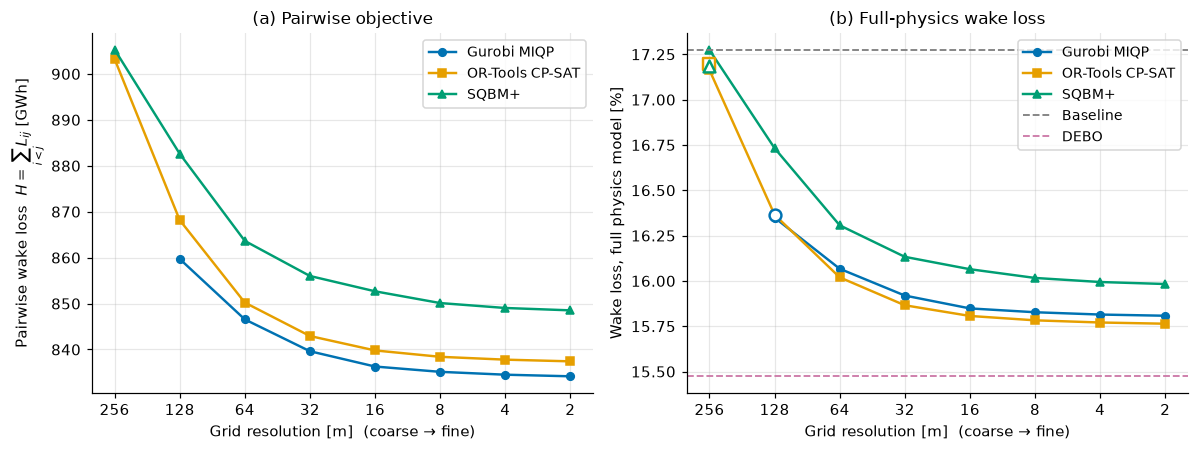

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
plot_metric(axes[0], "h_pairwise_gwh", "Pairwise wake loss  $H=\\sum_{i<j}L_{ij}$ [GWh]")
axes[0].set_title("(a) Pairwise objective")
plot_metric(axes[1], "wake_loss_pct", "Wake loss, full physics model [%]")
axes[1].axhline(BASELINE.wake_loss_pct, color=REF_COLORS["Baseline"], ls="--", lw=1.2, label="Baseline")
axes[1].axhline(BEST_REF.wake_loss_pct, color=REF_COLORS["DEBO"], ls="--", lw=1.2, label="DEBO")
axes[1].set_title("(b) Full-physics wake loss")
axes[0].legend(loc="upper right")
axes[1].legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "fig2_wake_vs_resolution")
plt.show()

## Fig. 3 — Fidelity of the pairwise model
Pairwise $H$ vs full-physics wake loss over all local-refinement layouts. A tight monotone relation justifies optimising the pairwise objective.

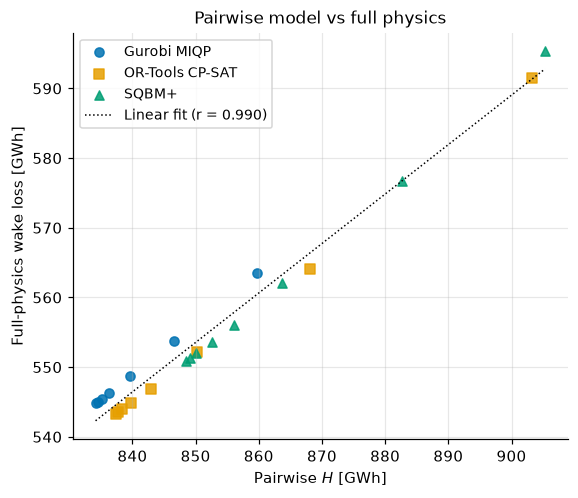

slope = 0.710, intercept = -49.8 GWh, Pearson r = 0.9905


In [6]:
fig, ax = plt.subplots(figsize=(5.8, 4.8))
for label, cfg in SOLVERS.items():
    d = df[df.solver == label]
    ax.scatter(d.h_pairwise_gwh, d.wake_loss_gwh, color=cfg["color"], marker=cfg["marker"],
               s=36, alpha=0.85, label=label)
dd = df.dropna(subset=["h_pairwise_gwh"])
x, y = dd.h_pairwise_gwh.values, dd.wake_loss_gwh.values
slope, icpt = np.polyfit(x, y, 1)
r = np.corrcoef(x, y)[0, 1]
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, slope * xs + icpt, color="k", lw=1, ls=":", label=f"Linear fit (r = {r:.3f})")
ax.set_xlabel("Pairwise $H$ [GWh]")
ax.set_ylabel("Full-physics wake loss [GWh]")
ax.set_title("Pairwise model vs full physics")
ax.legend()
save_fig(fig, "fig3_pairwise_fidelity")
plt.show()
print(f"slope = {slope:.3f}, intercept = {icpt:.1f} GWh, Pearson r = {r:.4f}")

## Fig. 4 — Final-layout comparison
Best layout (highest AEP) per solver, compared with Thomas et al. (2023).

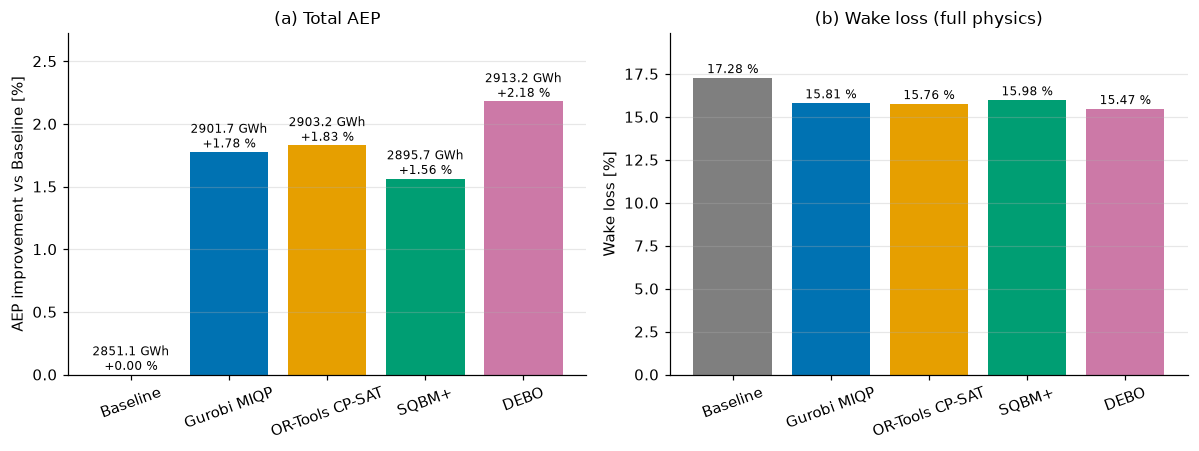

In [7]:
names = ["Baseline"] + list(SOLVERS) + ["DEBO"]
aep = [BASELINE.aep_gwh] + [best[l].aep_gwh for l in SOLVERS] + [BEST_REF.aep_gwh]
wl = [BASELINE.wake_loss_pct] + [best[l].wake_loss_pct for l in SOLVERS] + [BEST_REF.wake_loss_pct]
cols = [REF_COLORS["Baseline"]] + [SOLVERS[l]["color"] for l in SOLVERS] + [REF_COLORS["DEBO"]]
impr = [100 * (a / BASELINE.aep_gwh - 1) for a in aep]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bars = axes[0].bar(names, impr, color=cols)
for b, a, p in zip(bars, aep, impr):
    axes[0].annotate(f"{a:.1f} GWh\n+{p:.2f} %", (b.get_x() + b.get_width() / 2, p),
                     textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)
axes[0].set_ylabel("AEP improvement vs Baseline [%]")
axes[0].set_ylim(0, max(impr) * 1.25)
axes[0].set_title("(a) Total AEP")
bars = axes[1].bar(names, wl, color=cols)
for b, w in zip(bars, wl):
    axes[1].annotate(f"{w:.2f} %", (b.get_x() + b.get_width() / 2, w),
                     textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)
axes[1].set_ylabel("Wake loss [%]")
axes[1].set_ylim(0, max(wl) * 1.15)
axes[1].set_title("(b) Wake loss (full physics)")
for ax in axes:
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
save_fig(fig, "fig4_final_comparison")
plt.show()

## Fig. 5 — Pairwise wake matrices of the best layouts

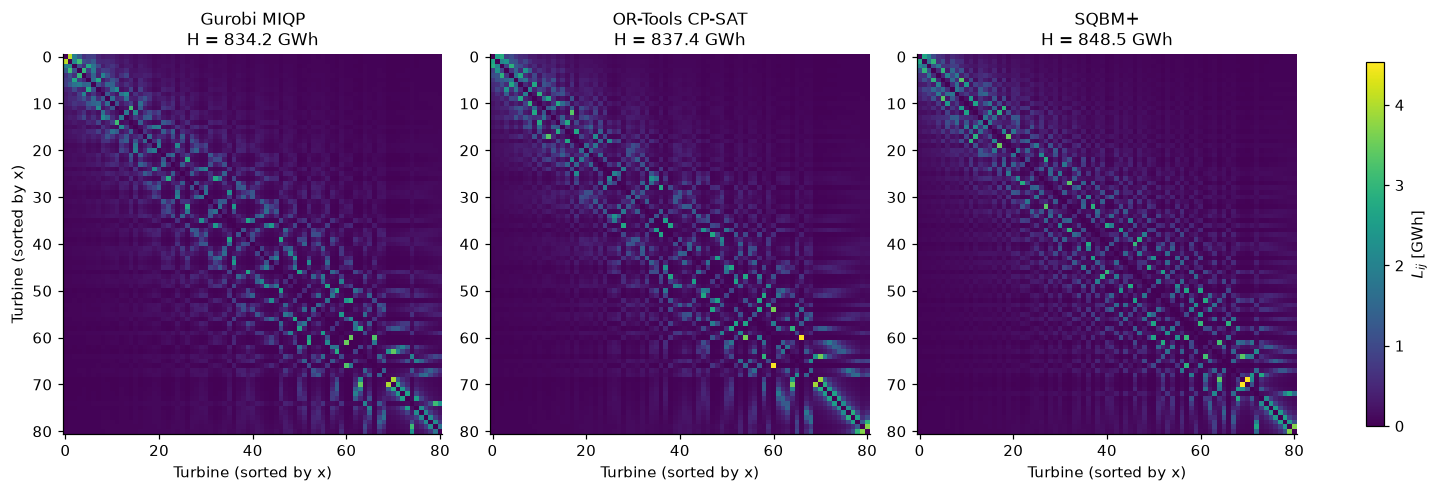

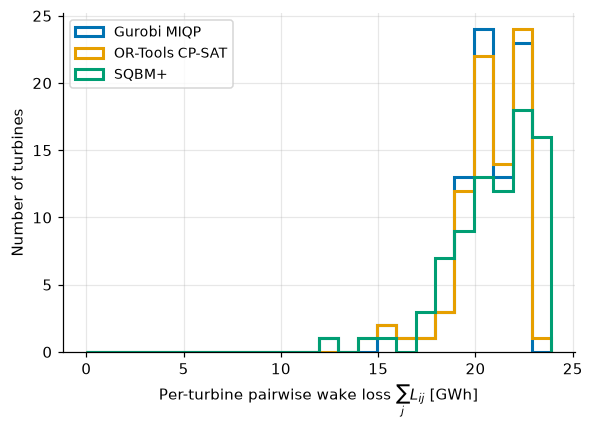

In [8]:
Lbest = {l: L / 1000.0 for l, L in L_best_mwh.items()}  # GWh
vmax = max(L.max() for L in Lbest.values())

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), constrained_layout=True)
for ax, (label, L) in zip(axes, Lbest.items()):
    order = np.argsort(load_layout_coordinates(best[label]["path"])[:, 0])  # sort turbines by x
    im = ax.imshow(L[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=vmax)
    ax.set_title(f"{label}\nH = {np.triu(L, 1).sum():.1f} GWh")
    ax.set_xlabel("Turbine (sorted by x)")
    ax.grid(False)
axes[0].set_ylabel("Turbine (sorted by x)")
fig.colorbar(im, ax=axes, shrink=0.85, label="$L_{ij}$ [GWh]")
save_fig(fig, "fig5a_pairwise_matrices")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
bins = np.linspace(0, max(L.sum(1).max() for L in Lbest.values()), 25)
for label, L in Lbest.items():
    ax.hist(L.sum(1), bins=bins, histtype="step", lw=2, color=SOLVERS[label]["color"], label=label)
ax.set_xlabel("Per-turbine pairwise wake loss $\\sum_j L_{ij}$ [GWh]")
ax.set_ylabel("Number of turbines")
ax.legend()
save_fig(fig, "fig5b_per_turbine_wake_hist")
plt.show()

## Fig. 6 — Best layouts, turbines coloured by wake loss

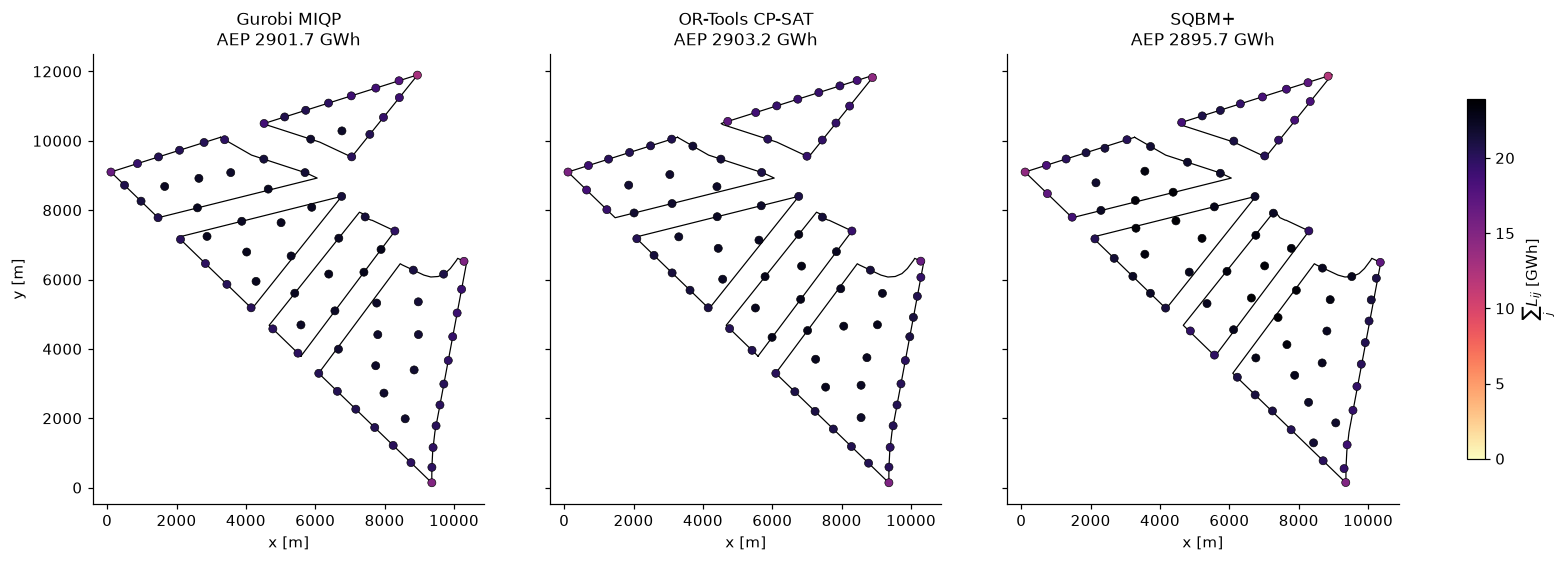

In [9]:
polygons, _ = get_farm_area()
vmax_t = max(L.sum(1).max() for L in Lbest.values())

fig, axes = plt.subplots(1, 3, figsize=(14, 5), constrained_layout=True, sharex=True, sharey=True)
for ax, label in zip(axes, SOLVERS):
    for p in polygons:
        ax.plot(*p.exterior.xy, color="k", lw=0.8)
    c = load_layout_coordinates(best[label]["path"])
    sc = ax.scatter(c[:, 0], c[:, 1], c=Lbest[label].sum(1), cmap="magma_r", vmin=0, vmax=vmax_t,
                    s=28, edgecolors="k", linewidths=0.4, zorder=3)
    ax.set_aspect("equal")
    ax.set_title(f"{label}\nAEP {best[label].aep_gwh:.1f} GWh")
    ax.set_xlabel("x [m]")
    ax.grid(False)
axes[0].set_ylabel("y [m]")
fig.colorbar(sc, ax=axes, shrink=0.8, label="$\\sum_j L_{ij}$ [GWh]")
save_fig(fig, "fig6_layouts")
plt.show()

## Fig. 7 — Feasibility: minimum inter-turbine distance

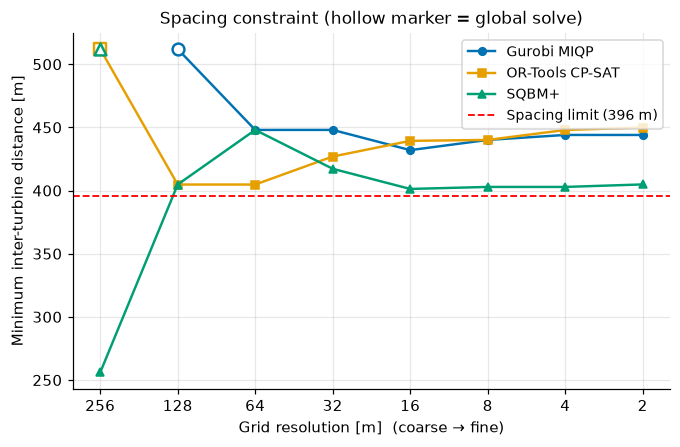

,solver,file,valid_cardinality,valid_spacing,valid_boundary,valid
0,Gurobi MIQP,gurobi_128_3600s.yaml,True,True,True,True
1,Gurobi MIQP,gurobi_local_128m_1800s_warmstart.yaml,True,True,True,True
2,Gurobi MIQP,gurobi_local_64m_1800s_warmstart.yaml,True,True,True,True
3,Gurobi MIQP,gurobi_local_32m_1800s_warmstart.yaml,True,True,True,True
4,Gurobi MIQP,gurobi_local_16m_1800s_warmstart.yaml,True,True,True,True
5,Gurobi MIQP,gurobi_local_8m_1800s_warmstart.yaml,True,True,True,True
6,Gurobi MIQP,gurobi_local_4m_1800s_warmstart.yaml,True,True,True,True
7,Gurobi MIQP,gurobi_local_2m_1800s_warmstart.yaml,True,True,True,True
8,OR-Tools CP-SAT,cpsat_256_3600s.yaml,True,True,True,True
9,OR-Tools CP-SAT,ortools_cpsat_local_256m_1800s_warmstart.yaml,True,True,True,True


In [10]:
fig, ax = plt.subplots(figsize=(7, 4.2))
plot_metric(ax, "min_distance_m", "Minimum inter-turbine distance [m]")
ax.axhline(MIN_SPACING, color="red", ls="--", lw=1.2, label=f"Spacing limit ({MIN_SPACING:.0f} m)")
ax.set_title("Spacing constraint (hollow marker = global solve)")
ax.legend(loc="upper right")
save_fig(fig, "fig7_min_distance")
plt.show()

df[["solver", "file", "valid_cardinality", "valid_spacing", "valid_boundary", "valid"]]

## Summary table

In [11]:
records = []
for label in SOLVERS:
    d = df[df.solver == label]
    b = best[label]
    records.append({
        "Method": label,
        "Best AEP [GWh]": b.aep_gwh,
        "Wake loss [%]": b.wake_loss_pct,
        "Pairwise H [GWh]": b.h_pairwise_gwh,
        "Best res. [m]": b.resolution,
        "Time limit global [s]": d[d.stage == "global"].time_limit_s.max(),
        "Time limit / local step [s]": d[d.stage == "local"].time_limit_s.max(),
        "Min dist. [m]": b.min_distance_m,
        "Valid": bool(b.valid),
    })
for name, r_ in (("Baseline (Thomas et al.)", BASELINE), ("DEBO (Thomas et al.)", BEST_REF)):
    records.append({"Method": name, "Best AEP [GWh]": r_.aep_gwh, "Wake loss [%]": r_.wake_loss_pct,
                    "Min dist. [m]": r_.min_distance_m, "Valid": bool(r_.valid)})
summary = pd.DataFrame(records)
summary["vs Baseline [%]"] = 100 * (summary["Best AEP [GWh]"] / BASELINE.aep_gwh - 1)
summary["Gap to DEBO [%]"] = 100 * (BEST_REF.aep_gwh - summary["Best AEP [GWh]"]) / BEST_REF.aep_gwh
summary.to_csv(FIG_DIR / "summary_table.csv", index=False)
(FIG_DIR / "summary_table.tex").write_text(summary.to_latex(index=False, float_format="%.2f", na_rep="--"))
summary.round(2)

,Method,Best AEP [GWh],Wake loss [%],Pairwise H [GWh],Best res. [m],Time limit global [s],Time limit / local step [s],Min dist. [m],Valid,vs Baseline [%],Gap to DEBO [%]
0,Gurobi MIQP,2901.71,15.81,834.17,2.0,NaN,1800.0,444.00,True,1.78,0.40
1,OR-Tools CP-SAT,2903.22,15.76,837.42,2.0,3600.0,1800.0,449.91,True,1.83,0.34
2,SQBM+,2895.68,15.98,848.52,2.0,NaN,60.0,404.86,True,1.56,0.60
3,Baseline (Thomas et al.),2851.10,17.28,NaN,NaN,NaN,NaN,499.86,False,0.00,2.13
4,DEBO (Thomas et al.),2913.22,15.47,NaN,NaN,NaN,NaN,407.55,True,2.18,0.00
